# Notebook 5 — Naive vs. Corrected: Does the Correction Actually Matter?

**Goal of this notebook:** this is the project's core comparison. We take a handful of pairs
that looked significant **naively** (p < 0.05) but did **not** survive Bonferroni correction,
build and backtest the exact same trading rule on them, and compare their real out-of-sample
performance against the Bonferroni-**corrected** pairs from Notebooks 3-4.

**The question:** did filtering out the pairs that only looked good by chance actually buy us
anything in terms of real trading performance? Or do naive and corrected pairs perform about
the same out of sample?

**Method (per the proposal's Phase 5):** compare the corrected group's mean Sharpe ratio
against the naive-only group's, using Welch's t-test, with a block bootstrap as a robustness
check.

In [1]:
!pip install -q statsmodels

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_rows', 200)
plt.rcParams['figure.dpi'] = 110
np.random.seed(42)

## 0. Google Drive setup

This notebook reads from **three** previous folders: `02_pair_selection` (cointegration
results + prices), `03_trading_rule_backtest` (corrected pairs' daily returns), and
`04_ttest_ci` (corrected pairs' Sharpe ratios). It saves its own output to
`05_naive_vs_corrected`.

In [3]:
PARENT_FOLDER_ID = '1w9Q2nfcNhew6hzx8eQSCINReUy3OUwE1'
FOLDER_PAIR_SELECTION = '02_pair_selection'
FOLDER_BACKTEST = '03_trading_rule_backtest'
FOLDER_TTEST = '04_ttest_ci'
THIS_NOTEBOOK_FOLDER = '05_naive_vs_corrected'

from google.colab import auth
auth.authenticate_user()

import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload, MediaIoBaseDownload
import io

creds, _ = google.auth.default()
drive_service = build('drive', 'v3', credentials=creds)


def get_or_create_subfolder(parent_id, name):
    query = (f"'{parent_id}' in parents and name='{name}' "
             "and mimeType='application/vnd.google-apps.folder' and trashed=false")
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    files = results.get('files', [])
    if files:
        return files[0]['id']
    metadata = {'name': name, 'mimeType': 'application/vnd.google-apps.folder', 'parents': [parent_id]}
    folder = drive_service.files().create(body=metadata, fields='id', supportsAllDrives=True).execute()
    print(f"Created new Drive subfolder: {name}")
    return folder['id']


def upload_file(local_path, folder_id):
    filename = local_path.split('/')[-1]
    query = f"'{folder_id}' in parents and name='{filename}' and trashed=false"
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    existing = results.get('files', [])
    media = MediaFileUpload(local_path, resumable=True)
    if existing:
        drive_service.files().update(fileId=existing[0]['id'], media_body=media, supportsAllDrives=True).execute()
    else:
        metadata = {'name': filename, 'parents': [folder_id]}
        drive_service.files().create(body=metadata, media_body=media, fields='id', supportsAllDrives=True).execute()
    print(f"Uploaded {filename} to Drive.")


def download_file(filename, folder_id, local_path=None):
    local_path = local_path or filename
    query = f"'{folder_id}' in parents and name='{filename}' and trashed=false"
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    files = results.get('files', [])
    if not files:
        raise FileNotFoundError(f"{filename} not found in Drive folder.")
    request = drive_service.files().get_media(fileId=files[0]['id'], supportsAllDrives=True)
    fh = io.FileIO(local_path, 'wb')
    downloader = MediaIoBaseDownload(fh, request)
    done = False
    while not done:
        _, done = downloader.next_chunk()
    print(f"Downloaded {filename} from Drive.")
    return local_path


folder_id_pair_selection = get_or_create_subfolder(PARENT_FOLDER_ID, FOLDER_PAIR_SELECTION)
folder_id_backtest = get_or_create_subfolder(PARENT_FOLDER_ID, FOLDER_BACKTEST)
folder_id_ttest = get_or_create_subfolder(PARENT_FOLDER_ID, FOLDER_TTEST)
this_folder_id = get_or_create_subfolder(PARENT_FOLDER_ID, THIS_NOTEBOOK_FOLDER)
print(f"Ready — reading from '{FOLDER_PAIR_SELECTION}', '{FOLDER_BACKTEST}', '{FOLDER_TTEST}';",
      f"saving to '{THIS_NOTEBOOK_FOLDER}'.")

Created new Drive subfolder: 05_naive_vs_corrected
Ready — reading from '02_pair_selection', '03_trading_rule_backtest', '04_ttest_ci'; saving to '05_naive_vs_corrected'.


## 1. Load everything needed

In [4]:
download_file('all_pairs_cointegration_results.csv', folder_id_pair_selection)
download_file('prices_train.csv', folder_id_pair_selection)
download_file('prices_verify.csv', folder_id_pair_selection)
download_file('daily_strategy_returns.csv', folder_id_backtest)
download_file('hypothesis_test_comparison.csv', folder_id_ttest)

all_pairs_results = pd.read_csv('all_pairs_cointegration_results.csv')
prices_train = pd.read_csv('prices_train.csv', index_col=0, parse_dates=True)
prices_verify = pd.read_csv('prices_verify.csv', index_col=0, parse_dates=True)
corrected_daily_returns = pd.read_csv('daily_strategy_returns.csv', index_col=0, parse_dates=True)
corrected_ttest = pd.read_csv('hypothesis_test_comparison.csv')

corrected_pairs = list(corrected_daily_returns.columns)
print(f"Corrected (Bonferroni-surviving) pairs: {corrected_pairs}")

Downloaded all_pairs_cointegration_results.csv from Drive.
Downloaded prices_train.csv from Drive.
Downloaded prices_verify.csv from Drive.
Downloaded daily_strategy_returns.csv from Drive.
Downloaded hypothesis_test_comparison.csv from Drive.
Corrected (Bonferroni-surviving) pairs: ['V-MA']


## 2. Pick the naive-only comparison group

Pairs that passed the naive p < 0.05 cutoff but did **not** survive Bonferroni correction. We
take the 5 strongest-looking naive-only pairs (smallest p-values) as the "naive group" — a
single naive pair would make for a very thin comparison, so a small group gives Welch's t-test
something real to compare against.

In [5]:
naive_only = all_pairs_results[
    (all_pairs_results['naive_significant']) & (~all_pairs_results['bonferroni_significant'])
].sort_values('p_value')

N_NAIVE_GROUP = min(5, len(naive_only))
naive_group_pairs = naive_only.head(N_NAIVE_GROUP)
print(f"Naive-only group ({N_NAIVE_GROUP} pairs):")
print(naive_group_pairs[['stock_1', 'stock_2', 'p_value']].to_string(index=False))

Naive-only group (5 pairs):
stock_1 stock_2  p_value
    WMT       V 0.000765
    WMT      MA 0.002599
    WMT      HD 0.010397
   COST     LOW 0.019456
   ROST       V 0.036259


## 3. Backtest the naive-only pairs (identical rule, same code as Notebook 3)

In [6]:
def estimate_hedge_ratio(stock_a, stock_b, prices_train):
    log_a = np.log(prices_train[stock_a].values)
    log_b = np.log(prices_train[stock_b].values)
    beta, const = np.polyfit(log_b, log_a, 1)
    return beta


def run_backtest(stock_a, stock_b, beta, prices_verify, window=60,
                  entry_z=2.0, exit_z=0.5, stop_z=4.0):
    log_a = np.log(prices_verify[stock_a])
    log_b = np.log(prices_verify[stock_b])
    spread = log_a - beta * log_b

    roll_mean = spread.rolling(window, min_periods=window).mean()
    roll_std = spread.rolling(window, min_periods=window).std()
    z = (spread - roll_mean) / roll_std

    position = np.zeros(len(z))
    current = 0
    for i in range(len(z)):
        zt = z.iloc[i]
        if np.isnan(zt):
            position[i] = 0
            continue
        if current == 0:
            if zt > entry_z:
                current = -1
            elif zt < -entry_z:
                current = 1
        else:
            if abs(zt) < exit_z or abs(zt) > stop_z:
                current = 0
        position[i] = current

    position_lagged = pd.Series(position, index=z.index).shift(1).fillna(0)
    spread_change = spread.diff()
    daily_return = (position_lagged * spread_change).fillna(0)

    return {'spread': spread, 'z': z, 'position': position_lagged, 'daily_return': daily_return}


naive_daily_returns = {}
for _, row in naive_group_pairs.iterrows():
    stock_a, stock_b = row['stock_1'], row['stock_2']
    pair_name = f"{stock_a}-{stock_b}"
    beta = estimate_hedge_ratio(stock_a, stock_b, prices_train)
    result = run_backtest(stock_a, stock_b, beta, prices_verify)
    naive_daily_returns[pair_name] = result['daily_return']

naive_daily_returns_df = pd.DataFrame(naive_daily_returns)
naive_pairs = list(naive_daily_returns_df.columns)
print(f"Backtested naive-only pairs: {naive_pairs}")

Backtested naive-only pairs: ['WMT-V', 'WMT-MA', 'WMT-HD', 'COST-LOW', 'ROST-V']


## 4. Sharpe ratio per pair, both groups

In [7]:
def annualized_sharpe(returns):
    returns = returns.dropna()
    if returns.std() == 0:
        return np.nan
    return (returns.mean() / returns.std()) * np.sqrt(252)


corrected_sharpes = {pair: annualized_sharpe(corrected_daily_returns[pair]) for pair in corrected_pairs}
naive_sharpes = {pair: annualized_sharpe(naive_daily_returns_df[pair]) for pair in naive_pairs}

sharpe_summary = pd.DataFrame({
    'pair': list(corrected_sharpes.keys()) + list(naive_sharpes.keys()),
    'group': ['Corrected'] * len(corrected_sharpes) + ['Naive-only'] * len(naive_sharpes),
    'sharpe_annualized': list(corrected_sharpes.values()) + list(naive_sharpes.values()),
})
sharpe_summary

,pair,group,sharpe_annualized
0,V-MA,Corrected,0.962003
1,WMT-V,Naive-only,-0.359507
2,WMT-MA,Naive-only,-0.103569
3,WMT-HD,Naive-only,0.096900
4,COST-LOW,Naive-only,0.020442
5,ROST-V,Naive-only,0.671922


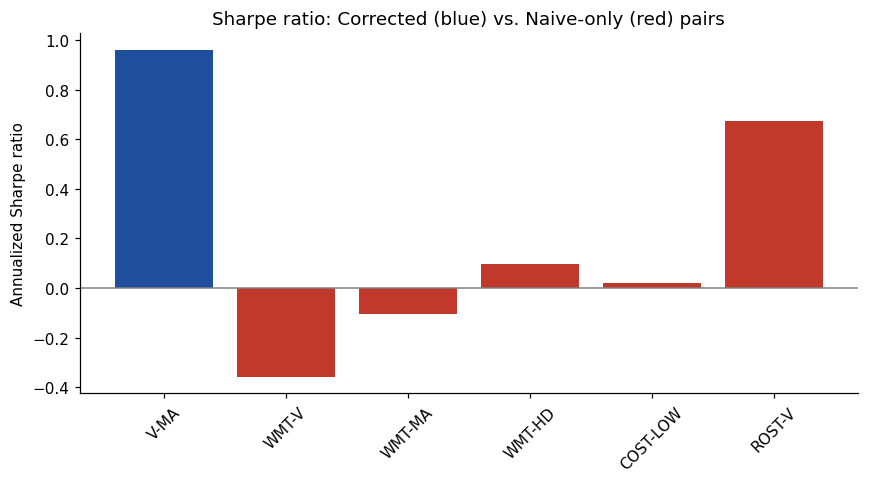

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ['#1f4e9c' if g == 'Corrected' else '#c0392b' for g in sharpe_summary['group']]
bars = ax.bar(sharpe_summary['pair'], sharpe_summary['sharpe_annualized'], color=colors)
ax.axhline(0, color='gray', linewidth=1)
ax.set_ylabel('Annualized Sharpe ratio')
ax.set_title('Sharpe ratio: Corrected (blue) vs. Naive-only (red) pairs')
ax.tick_params(axis='x', rotation=45)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 5. Equity curves: corrected group vs. naive-only group

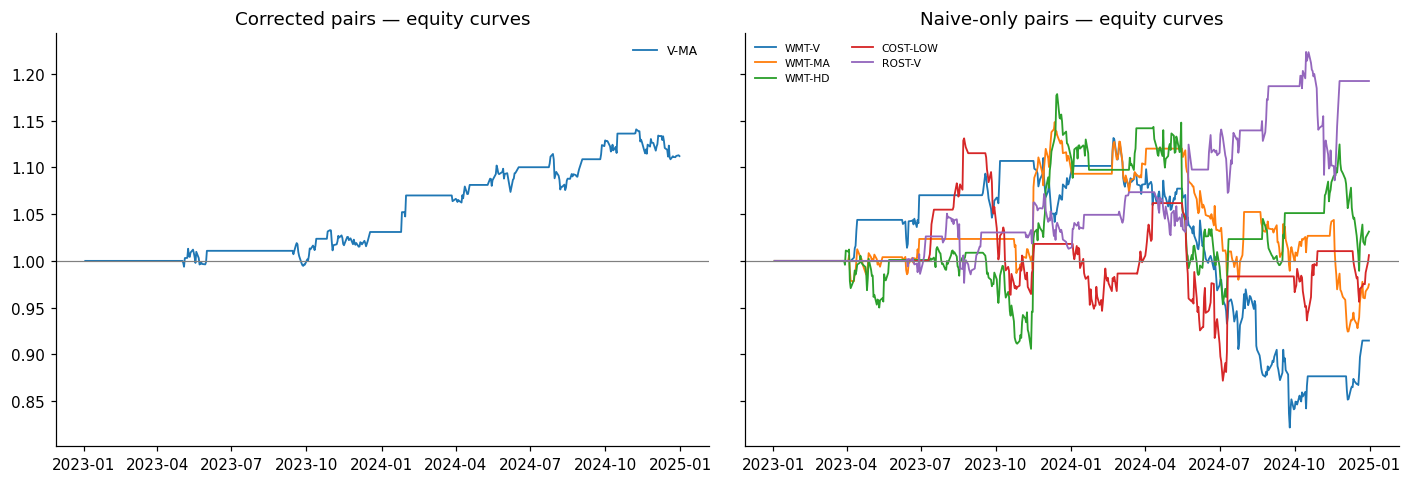

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for pair in corrected_pairs:
    equity = np.exp(corrected_daily_returns[pair].fillna(0).cumsum())
    axes[0].plot(equity.index, equity.values, label=pair, linewidth=1.2)
axes[0].axhline(1.0, color='gray', linewidth=0.8)
axes[0].set_title('Corrected pairs — equity curves')
axes[0].legend(fontsize=8, frameon=False)
axes[0].spines[['top', 'right']].set_visible(False)

for pair in naive_pairs:
    equity = np.exp(naive_daily_returns_df[pair].fillna(0).cumsum())
    axes[1].plot(equity.index, equity.values, label=pair, linewidth=1.2)
axes[1].axhline(1.0, color='gray', linewidth=0.8)
axes[1].set_title('Naive-only pairs — equity curves')
axes[1].legend(fontsize=7, frameon=False, ncol=2)
axes[1].spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

## 6. Does statistical significance predict real performance?

A scatter of each pair's cointegration p-value (how strongly it passed the original test)
against its realized Sharpe ratio — across both groups.

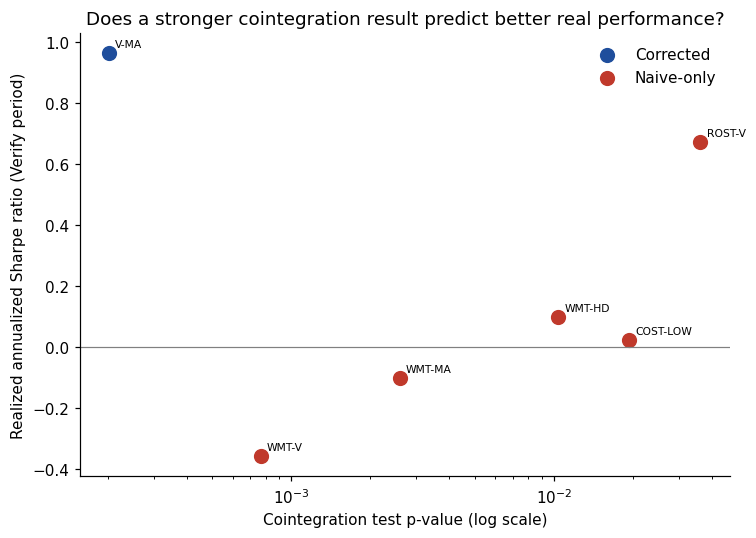

In [10]:
pvalue_lookup = all_pairs_results.set_index(
    all_pairs_results['stock_1'] + '-' + all_pairs_results['stock_2']
)['p_value']

fig, ax = plt.subplots(figsize=(7, 5))
for pair in corrected_pairs:
    ax.scatter(pvalue_lookup[pair], corrected_sharpes[pair], color='#1f4e9c', s=80,
               label='Corrected' if pair == corrected_pairs[0] else None)
    ax.annotate(pair, (pvalue_lookup[pair], corrected_sharpes[pair]), fontsize=7, xytext=(4, 4), textcoords='offset points')
for pair in naive_pairs:
    ax.scatter(pvalue_lookup[pair], naive_sharpes[pair], color='#c0392b', s=80,
               label='Naive-only' if pair == naive_pairs[0] else None)
    ax.annotate(pair, (pvalue_lookup[pair], naive_sharpes[pair]), fontsize=7, xytext=(4, 4), textcoords='offset points')

ax.set_xscale('log')
ax.set_xlabel('Cointegration test p-value (log scale)')
ax.set_ylabel('Realized annualized Sharpe ratio (Verify period)')
ax.set_title('Does a stronger cointegration result predict better real performance?')
ax.axhline(0, color='gray', linewidth=0.8)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 7. Formal comparison: Welch's t-test on Sharpe ratios

$$H_0: \mu_{\text{corrected}} = \mu_{\text{naive}} \quad \text{vs.} \quad H_1: \mu_{\text{corrected}} > \mu_{\text{naive}}$$

**Caveat worth stating plainly:** with only 2 corrected pairs and 5 naive-only pairs, this test
has very little statistical power — it's included because the proposal specifies it, not
because a 2-vs-5 comparison is a strong basis for a confident conclusion on its own. The pooled
daily-return version below and the bootstrap check give a larger-sample alternative view.

In [11]:
corrected_sharpe_values = np.array(list(corrected_sharpes.values()))
naive_sharpe_values = np.array(list(naive_sharpes.values()))

t_stat, p_value_two_sided = stats.ttest_ind(corrected_sharpe_values, naive_sharpe_values, equal_var=False)
p_value_one_sided = p_value_two_sided / 2 if t_stat > 0 else 1 - p_value_two_sided / 2

print("Welch's t-test on per-pair Sharpe ratios (Corrected vs. Naive-only):")
print(f"  Corrected mean Sharpe: {corrected_sharpe_values.mean():.3f}  (n={len(corrected_sharpe_values)})")
print(f"  Naive-only mean Sharpe: {naive_sharpe_values.mean():.3f}  (n={len(naive_sharpe_values)})")
print(f"  t-statistic: {t_stat:.3f}")
print(f"  One-sided p-value (corrected > naive): {p_value_one_sided:.4f}")

Welch's t-test on per-pair Sharpe ratios (Corrected vs. Naive-only):
  Corrected mean Sharpe: 0.962  (n=1)
  Naive-only mean Sharpe: 0.065  (n=5)
  t-statistic: nan
  One-sided p-value (corrected > naive): nan


### A larger-sample alternative: pooled daily returns

Instead of one Sharpe ratio per pair (n=2 vs n=5), pool every daily return from every pair
within each group and compare the pooled means directly. Far more observations, at the cost of
treating days from different pairs as exchangeable.

In [12]:
pooled_corrected = corrected_daily_returns[corrected_pairs].values.flatten()
pooled_corrected = pooled_corrected[~np.isnan(pooled_corrected)]
pooled_naive = naive_daily_returns_df[naive_pairs].values.flatten()
pooled_naive = pooled_naive[~np.isnan(pooled_naive)]

t_stat_pooled, p_value_pooled = stats.ttest_ind(pooled_corrected, pooled_naive, equal_var=False)
print("Welch's t-test on pooled daily returns (Corrected vs. Naive-only):")
print(f"  Corrected pooled mean daily return: {pooled_corrected.mean():.6f}  (n={len(pooled_corrected)})")
print(f"  Naive-only pooled mean daily return: {pooled_naive.mean():.6f}  (n={len(pooled_naive)})")
print(f"  t-statistic: {t_stat_pooled:.3f}, two-sided p-value: {p_value_pooled:.4f}")

Welch's t-test on pooled daily returns (Corrected vs. Naive-only):
  Corrected pooled mean daily return: 0.000212  (n=502)
  Naive-only pooled mean daily return: 0.000039  (n=2510)
  t-statistic: 0.737, two-sided p-value: 0.4611


## 8. Robustness check: block bootstrap on the group difference

Resample blocks of consecutive days independently within each pair's return series, rebuild
each group's pooled mean, and look at the distribution of (corrected mean - naive mean).

In [13]:
def block_bootstrap_group_mean(returns_df, block_size=20, n_boot=2000):
    """Bootstraps the pooled mean return across all pairs/columns in returns_df."""
    arrays = [returns_df[col].dropna().values for col in returns_df.columns]
    boot_means = np.empty(n_boot)
    for b in range(n_boot):
        samples = []
        for arr in arrays:
            n = len(arr)
            max_start = max(n - block_size, 0)
            n_blocks_needed = int(np.ceil(n / block_size))
            starts = np.random.randint(0, max_start + 1, size=n_blocks_needed)
            sample = np.concatenate([arr[s:s + block_size] for s in starts])[:n]
            samples.append(sample)
        boot_means[b] = np.concatenate(samples).mean()
    return boot_means


boot_corrected = block_bootstrap_group_mean(corrected_daily_returns[corrected_pairs])
boot_naive = block_bootstrap_group_mean(naive_daily_returns_df[naive_pairs])
boot_diff = boot_corrected - boot_naive

ci_low, ci_high = np.percentile(boot_diff, [2.5, 97.5])
print(f"Bootstrap 95% CI for (Corrected mean - Naive-only mean): [{ci_low:.6f}, {ci_high:.6f}]")
print(f"Share of bootstrap draws where corrected > naive: {(boot_diff > 0).mean():.1%}")

Bootstrap 95% CI for (Corrected mean - Naive-only mean): [-0.000179, 0.000603]
Share of bootstrap draws where corrected > naive: 86.1%


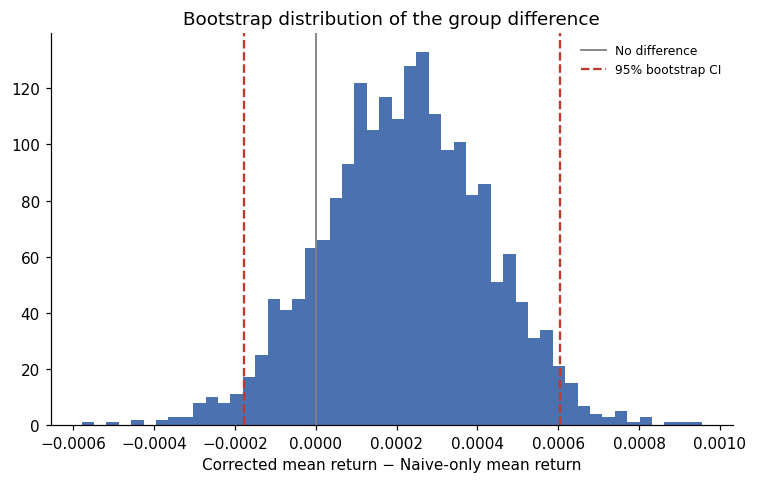

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(boot_diff, bins=50, color='#1f4e9c', alpha=0.8)
ax.axvline(0, color='gray', linewidth=1.2, label='No difference')
ax.axvline(ci_low, color='#c0392b', linestyle='--', label='95% bootstrap CI')
ax.axvline(ci_high, color='#c0392b', linestyle='--')
ax.set_xlabel('Corrected mean return − Naive-only mean return')
ax.set_title('Bootstrap distribution of the group difference')
ax.legend(fontsize=8, frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 9. Save final comparison results

In [15]:
final_comparison = {
    'corrected_pairs': corrected_pairs,
    'naive_pairs': naive_pairs,
    'corrected_mean_sharpe': corrected_sharpe_values.mean(),
    'naive_mean_sharpe': naive_sharpe_values.mean(),
    'welch_sharpe_t_stat': t_stat,
    'welch_sharpe_p_value_one_sided': p_value_one_sided,
    'welch_pooled_t_stat': t_stat_pooled,
    'welch_pooled_p_value_two_sided': p_value_pooled,
    'bootstrap_diff_ci_low': ci_low,
    'bootstrap_diff_ci_high': ci_high,
    'bootstrap_share_corrected_higher': (boot_diff > 0).mean(),
}

pd.DataFrame([final_comparison]).to_csv('naive_vs_corrected_summary.csv', index=False)
sharpe_summary.to_csv('sharpe_by_pair.csv', index=False)
naive_daily_returns_df.to_csv('naive_group_daily_returns.csv')

output_files = ['naive_vs_corrected_summary.csv', 'sharpe_by_pair.csv', 'naive_group_daily_returns.csv']
for fname in output_files:
    upload_file(fname, this_folder_id)

print(f"Saved locally and uploaded to Drive ({THIS_NOTEBOOK_FOLDER}): {', '.join(output_files)}")

Uploaded naive_vs_corrected_summary.csv to Drive.
Uploaded sharpe_by_pair.csv to Drive.
Uploaded naive_group_daily_returns.csv to Drive.
Saved locally and uploaded to Drive (05_naive_vs_corrected): naive_vs_corrected_summary.csv, sharpe_by_pair.csv, naive_group_daily_returns.csv


## Summary

This closes the core analysis pipeline:
1. **Notebook 1** — explored the data
2. **Notebook 2** — found candidate pairs (naive vs. Bonferroni vs. FDR), addressing
   independence via the ADF test's own lag structure and dual regression orderings
3. **Notebook 3** — built and backtested the trading rule on untouched Verify data
4. **Notebook 4** — tested whether the corrected pairs' returns are real, with independence
   handled via Newey-West standard errors and a block bootstrap
5. **Notebook 5** — compared corrected vs. naive-only pairs directly, to see whether the
   multiple-testing correction actually mattered for real, out-of-sample performance

The optional ANOVA stretch step (Phase 6 in the proposal — testing lookback window and entry
threshold as two factors) can be added as a Notebook 6 later if time permits.